# Understanding the Frozen DINOv2 Baseline

This notebook walks through the complete Session 1 embedding and retrieval result. The committed notebook includes its executed outputs and all 98 reviewed photographs so the experiment can be understood without recreating my local environment.

The goal is not just to report one accuracy number. We will inspect what an embedding looks like, calculate cosine similarity by hand, compare images from the same and different dolls, visualize the full similarity structure, reconstruct identity aggregation, explain every metric, and review every incorrect prediction.

> **Important limitation:** Session 1 queries and references share the same background, lighting, and capture period. These results confirm that the pipeline works. They do not measure generalization to new photographs.

## Publication and image rights

This is an independent educational fan project and is not affiliated with Nagano, Chiikawa, or their official rights holders.

The photographs displayed in this notebook were taken by Emma Tong and were deliberately selected for publication with this project. © 2026 Emma Tong. All rights reserved. The original HEIC files and the standalone prepared dataset remain outside Git.

## 1. Pipeline overview

The baseline follows this path:

```text
prepared JPEG
      ↓
pinned DINOv2 Small image processor
      ↓
frozen vision transformer
      ↓
384 dimensional CLS embedding
      ↓
unit length normalization
      ↓
cosine similarity against gallery images
      ↓
best reference score for each identity
      ↓
ranked doll identities
```

No parameters are trained. The model is used only as a feature extractor.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

from usagi_visual_identifier.data.loaders import load_catalog_csv
from usagi_visual_identifier.embeddings import load_embedding_artifact

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 90
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the project configuration."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from inside the project repository.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
PRIVATE_ROOT = PROJECT_ROOT / "data" / "private"
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"

embedding_path = ARTIFACT_ROOT / "embeddings/facebook_dinov2-small/embeddings.npz"
metadata_path = ARTIFACT_ROOT / "embeddings/facebook_dinov2-small/metadata.json"
report_path = ARTIFACT_ROOT / "evaluations/dinov2_small/session_001_leave_one_out.json"

required = [
    PRIVATE_ROOT / "catalog.csv",
    PROCESSED_ROOT / "images.csv",
    embedding_path,
    metadata_path,
    report_path,
]
missing = [path for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing local artifacts. Run Prepare Session 1 and Build DINOv2 Embedding Baseline first:\n"
        + "\n".join(str(path) for path in missing)
    )

artifact = load_embedding_artifact(
    artifact_path=embedding_path,
    metadata_path=metadata_path,
)
report = json.loads(report_path.read_text(encoding="utf-8"))
catalog = load_catalog_csv(path=PRIVATE_ROOT / "catalog.csv")
catalog_names = {item.catalog_id: item.display_name for item in catalog.items}
image_index = {image_id: index for index, image_id in enumerate(artifact.image_ids)}


def image_path(image_id: str) -> Path:
    """Resolve one saved image ID to its local prepared JPEG."""
    index = image_index[image_id]
    return PROCESSED_ROOT / artifact.processed_relative_paths[index]


def draw_image(axis, image_id: str, title: str) -> None:
    """Draw one private image on a Matplotlib axis."""
    with Image.open(image_path(image_id)) as opened:
        axis.imshow(opened.convert("RGB"))
    axis.set_title(title)
    axis.axis("off")


print(
    f"Loaded {len(artifact.image_ids)} embeddings with shape {artifact.embeddings.shape}."
)

Loaded 98 embeddings with shape (98, 384).


## 2. Complete Session 1 gallery

These galleries show all 98 photographs used in the baseline. Each identity has 14 views. The order differs slightly between dolls because the number identifies the photograph rather than a required camera angle.

Showing the complete session makes the data collection choices visible. It also helps reveal repeated conditions such as the shared background, hand, and blanket that may influence similarity.

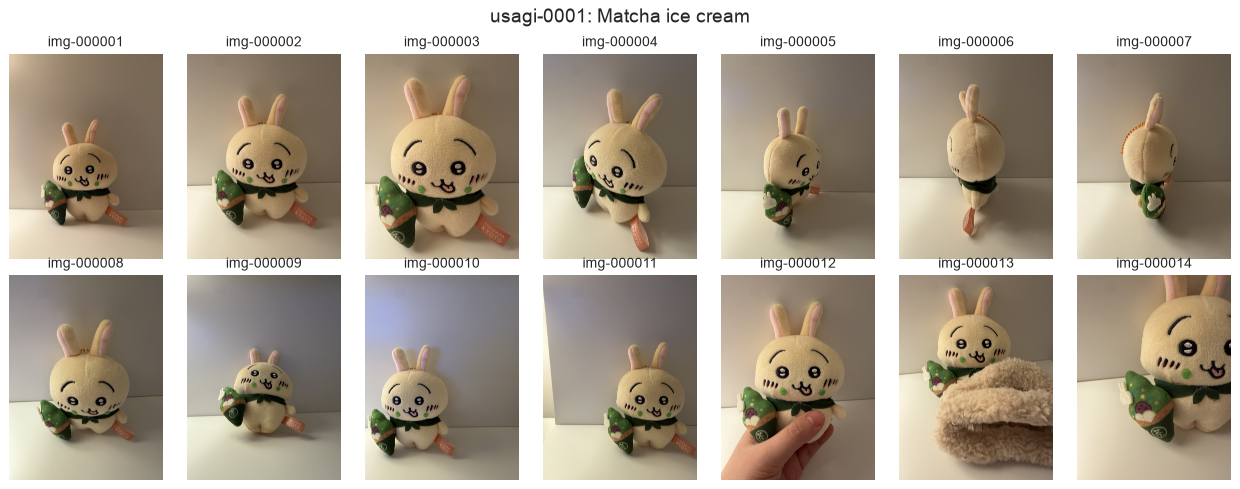

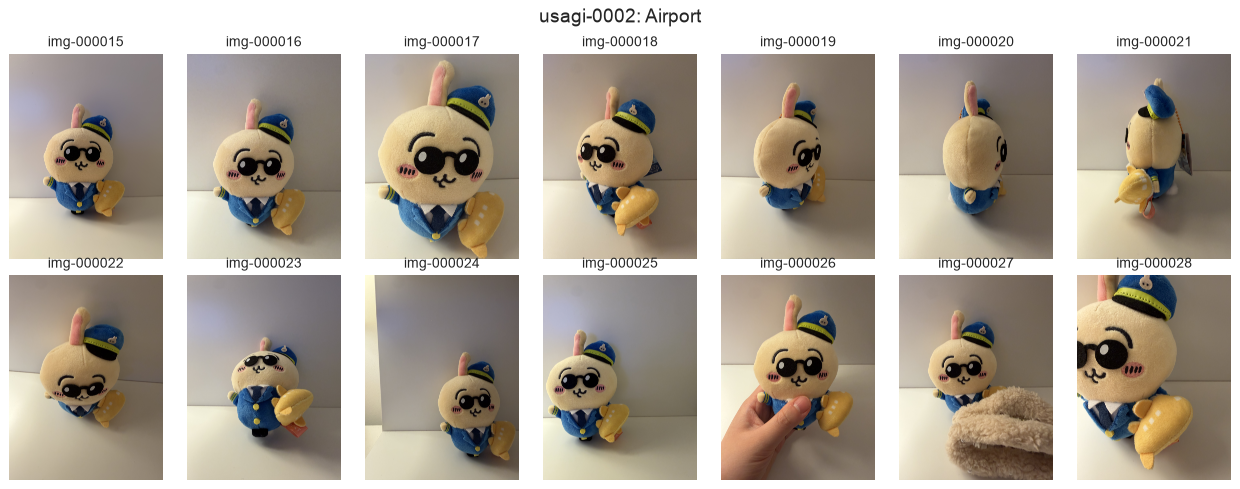

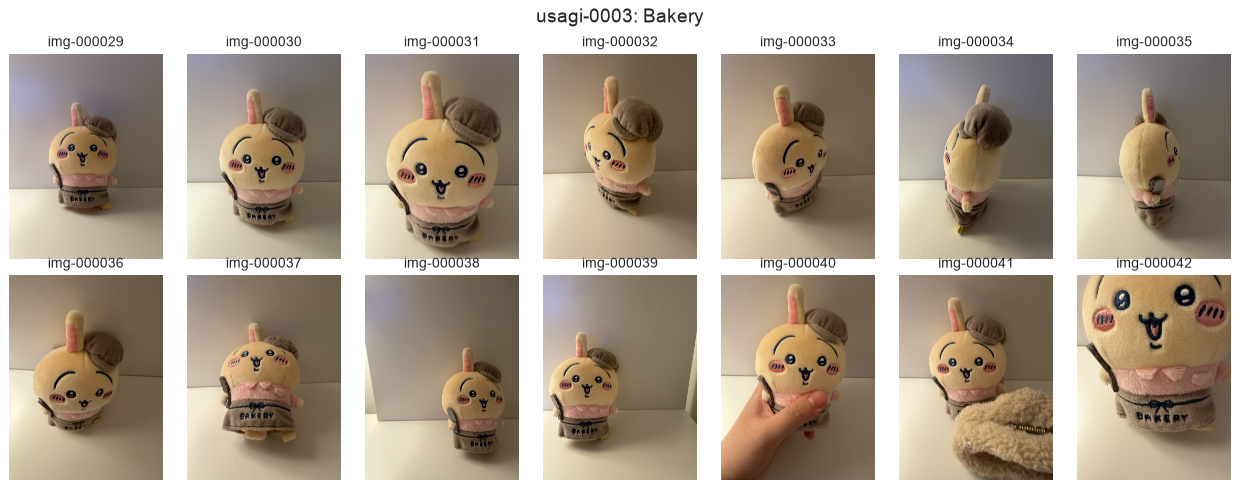

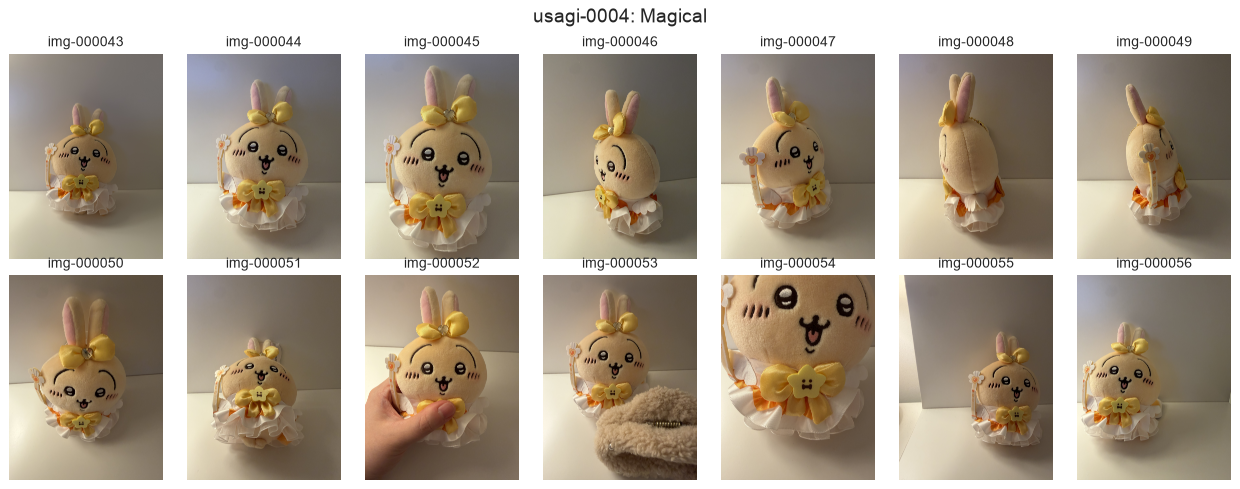

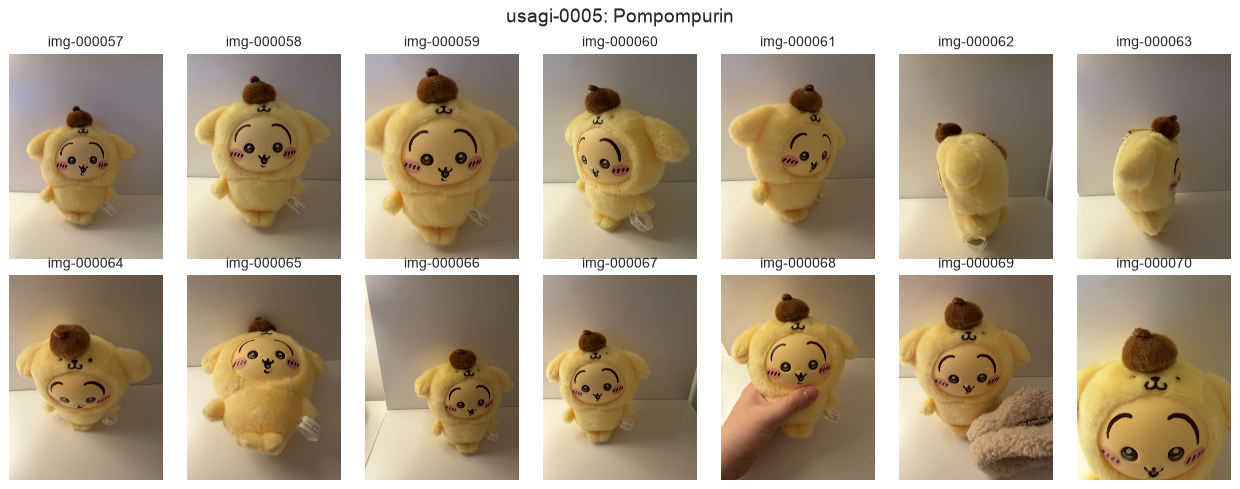

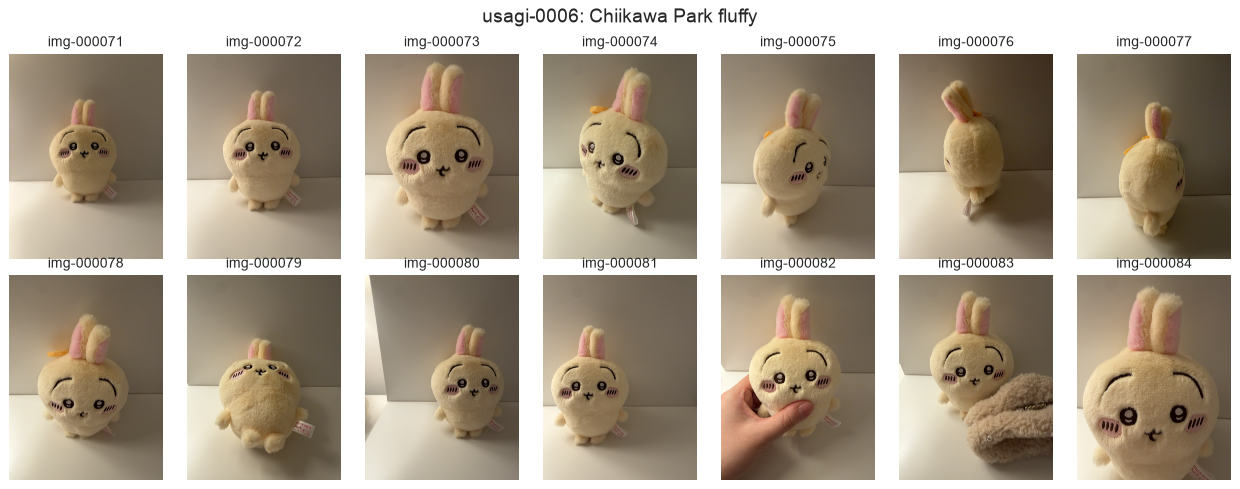

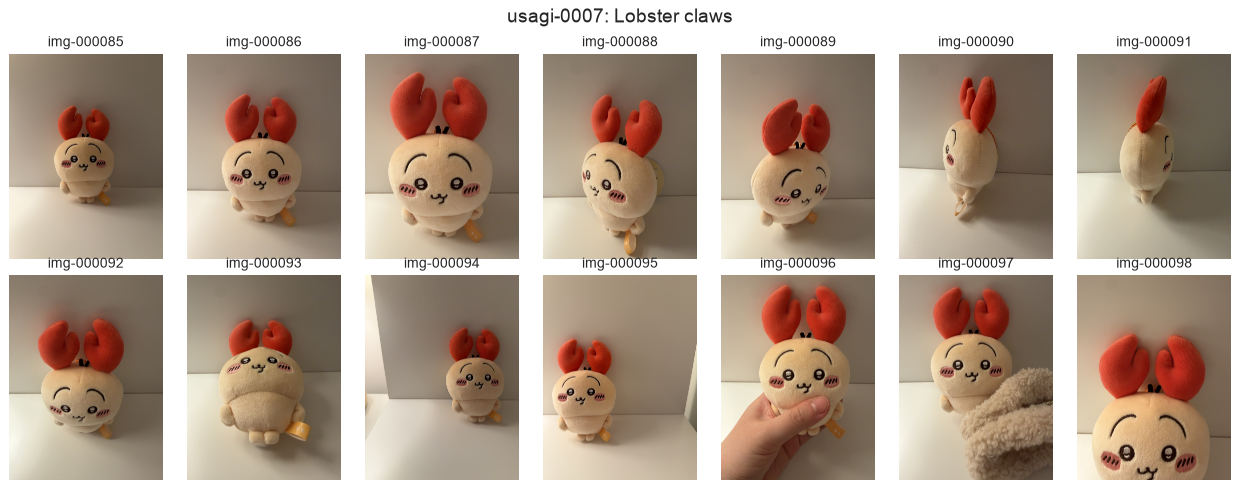

In [2]:
for identity in sorted(set(artifact.identity_ids)):
    identity_image_ids = [
        image_id
        for image_id, image_identity in zip(
            artifact.image_ids, artifact.identity_ids, strict=True
        )
        if image_identity == identity
    ]
    fig, axes = plt.subplots(2, 7, figsize=(14, 5.5))
    for axis, image_id in zip(axes.flat, identity_image_ids, strict=True):
        draw_image(axis, image_id, image_id)
    fig.suptitle(
        f"{identity}: {catalog_names.get(identity, identity)}",
        fontsize=15,
    )
    plt.tight_layout()
    plt.show()

## 3. Reproducibility metadata

An embedding result is meaningful only when we know exactly which model, dataset, and transformation produced it. The metadata also lets us detect stale artifacts after the catalog or manifest changes.

In [3]:
metadata_table = pd.DataFrame(
    {
        "value": {
            "model": artifact.metadata["model_id"],
            "model revision": artifact.metadata["model_revision"],
            "device": artifact.metadata["device"],
            "image count": artifact.metadata["image_count"],
            "embedding dimension": artifact.metadata["embedding_dimension"],
            "pooling": artifact.metadata["embedding_pooling"],
            "unit normalized": artifact.metadata["l2_normalized"],
            "embedding time in seconds": round(
                float(artifact.metadata["elapsed_seconds"]), 3
            ),
            "images per second": round(
                float(artifact.metadata["images_per_second"]), 2
            ),
            "dataset fingerprint": artifact.metadata["dataset_fingerprint"],
        }
    }
)
display(metadata_table)

,value
model,facebook/dinov2-small
model revision,ed25f3a31f01632728cabb09d1542f84ab7b0056
device,mps
image count,98
embedding dimension,384
pooling,cls_token
unit normalized,True
embedding time in seconds,4.782
images per second,20.5
dataset fingerprint,7cc699a1034dca6962262616bae80c256affc5ac0c48bb...


## 4. What one embedding looks like

An embedding is not a list of human named attributes such as “yellow bow” or “blue hat.” It is a learned numeric representation. Each dimension participates in many visual patterns, and one dimension usually has no useful interpretation by itself.

The useful information comes from the **direction of the complete vector**. Similar image directions should represent similar visual content.

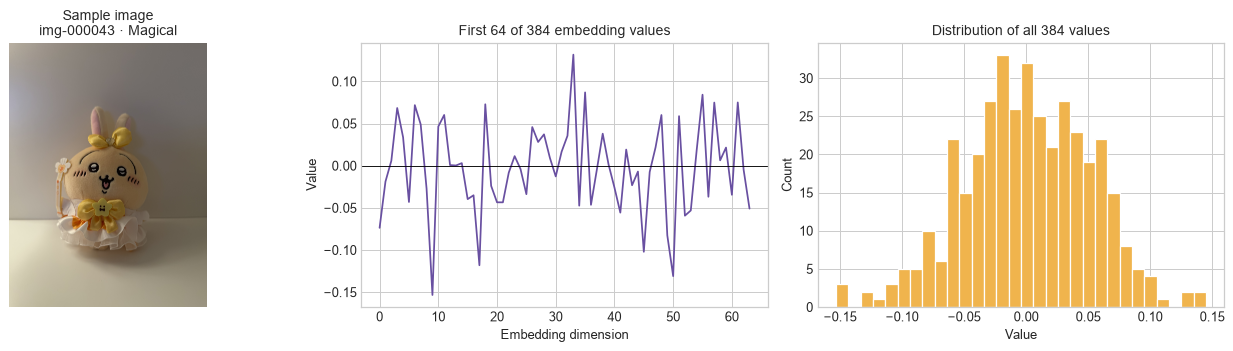

Shape: (384,)
L2 norm: 1.000000
First 12 values: [-0.0737 -0.0189  0.0058  0.0684  0.0337 -0.0431  0.0718  0.0489 -0.0272
 -0.1534  0.0464  0.0602]


In [4]:
sample_identity = (
    "usagi-0004" if "usagi-0004" in artifact.identity_ids else artifact.identity_ids[0]
)
sample_index = artifact.identity_ids.index(sample_identity)
sample_id = artifact.image_ids[sample_index]
sample_embedding = artifact.embeddings[sample_index]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
draw_image(
    axes[0],
    sample_id,
    f"Sample image\n{sample_id} · {catalog_names[sample_identity]}",
)
axes[1].plot(np.arange(64), sample_embedding[:64], color="#6950a1", linewidth=1.4)
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set_title("First 64 of 384 embedding values")
axes[1].set_xlabel("Embedding dimension")
axes[1].set_ylabel("Value")
axes[2].hist(sample_embedding, bins=30, color="#f0b44d", edgecolor="white")
axes[2].set_title("Distribution of all 384 values")
axes[2].set_xlabel("Value")
axes[2].set_ylabel("Count")
plt.tight_layout()
plt.show()

print(f"Shape: {sample_embedding.shape}")
print(f"L2 norm: {np.linalg.norm(sample_embedding):.6f}")
print("First 12 values:", np.round(sample_embedding[:12], 4))

The L2 norm should be approximately `1.0` because every embedding is normalized. Normalization makes the dot product equal cosine similarity and prevents vector magnitude from dominating the comparison.

## 5. Cosine similarity with real examples

For normalized vectors $a$ and $b$:

$$\operatorname{cosine}(a,b) = a \cdot b$$

The theoretical range is from negative one to positive one:

1. `1.0` means the vectors point in the same direction.
2. `0.0` means they are orthogonal.
3. `-1.0` means they point in opposite directions.

Vision embeddings often occupy a much narrower positive range. There is no universal score that means “same doll.” We must compare score distributions and choose any future threshold using independent validation data.

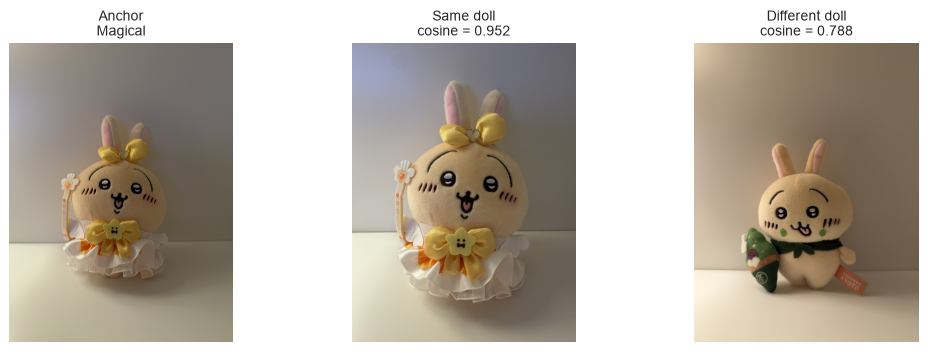

,comparison,cosine similarity
0,same doll,0.9524
1,different doll,0.7879


In [5]:
same_indices = [
    index
    for index, identity in enumerate(artifact.identity_ids)
    if identity == sample_identity
]
first_index, second_index = same_indices[:2]
different_index = next(
    index
    for index, identity in enumerate(artifact.identity_ids)
    if identity != sample_identity
)

same_score = float(artifact.embeddings[first_index] @ artifact.embeddings[second_index])
different_score = float(
    artifact.embeddings[first_index] @ artifact.embeddings[different_index]
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
draw_image(
    axes[0],
    artifact.image_ids[first_index],
    f"Anchor\n{catalog_names[artifact.identity_ids[first_index]]}",
)
draw_image(
    axes[1],
    artifact.image_ids[second_index],
    f"Same doll\ncosine = {same_score:.3f}",
)
draw_image(
    axes[2],
    artifact.image_ids[different_index],
    f"Different doll\ncosine = {different_score:.3f}",
)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame(
    {
        "comparison": ["same doll", "different doll"],
        "cosine similarity": [same_score, different_score],
    }
)
display(comparison.style.format({"cosine similarity": "{:.4f}"}))

A single pair can be misleading, so the next plot compares every unique pair. The overlap is especially important. Overlap means some photographs of different dolls look more similar to the encoder than some photographs of the same doll.

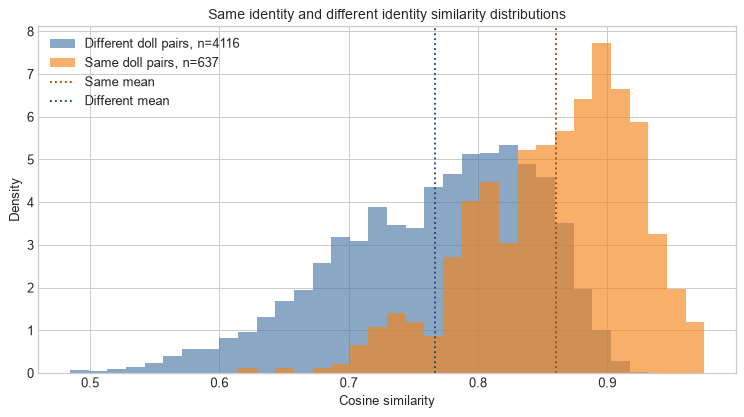

,pair type,mean,minimum,maximum
0,same doll,0.8604,0.6219,0.9749
1,different doll,0.7665,0.4845,0.9240


In [6]:
similarity_matrix = artifact.embeddings @ artifact.embeddings.T
upper_row, upper_column = np.triu_indices(len(artifact.image_ids), k=1)
pair_scores = similarity_matrix[upper_row, upper_column]
same_mask = (
    np.asarray(artifact.identity_ids)[upper_row]
    == np.asarray(artifact.identity_ids)[upper_column]
)
same_scores = pair_scores[same_mask]
different_scores = pair_scores[~same_mask]

bins = np.linspace(float(pair_scores.min()), float(pair_scores.max()), 35)
plt.figure(figsize=(10, 5))
plt.hist(
    different_scores,
    bins=bins,
    alpha=0.65,
    density=True,
    label=f"Different doll pairs, n={len(different_scores)}",
    color="#4c78a8",
)
plt.hist(
    same_scores,
    bins=bins,
    alpha=0.65,
    density=True,
    label=f"Same doll pairs, n={len(same_scores)}",
    color="#f58518",
)
plt.axvline(same_scores.mean(), color="#a34a00", linestyle=":", label="Same mean")
plt.axvline(
    different_scores.mean(), color="#1c4d75", linestyle=":", label="Different mean"
)
plt.xlabel("Cosine similarity")
plt.ylabel("Density")
plt.title("Same identity and different identity similarity distributions")
plt.legend()
plt.show()

display(
    pd.DataFrame(
        {
            "pair type": ["same doll", "different doll"],
            "mean": [same_scores.mean(), different_scores.mean()],
            "minimum": [same_scores.min(), different_scores.min()],
            "maximum": [same_scores.max(), different_scores.max()],
        }
    ).style.format({"mean": "{:.4f}", "minimum": "{:.4f}", "maximum": "{:.4f}"})
)

## 6. Full image similarity map

Rows and columns are ordered by identity. Bright square blocks along the diagonal mean photographs of the same doll are similar. Bright areas away from the diagonal reveal identities or photographic conditions that the encoder may confuse.

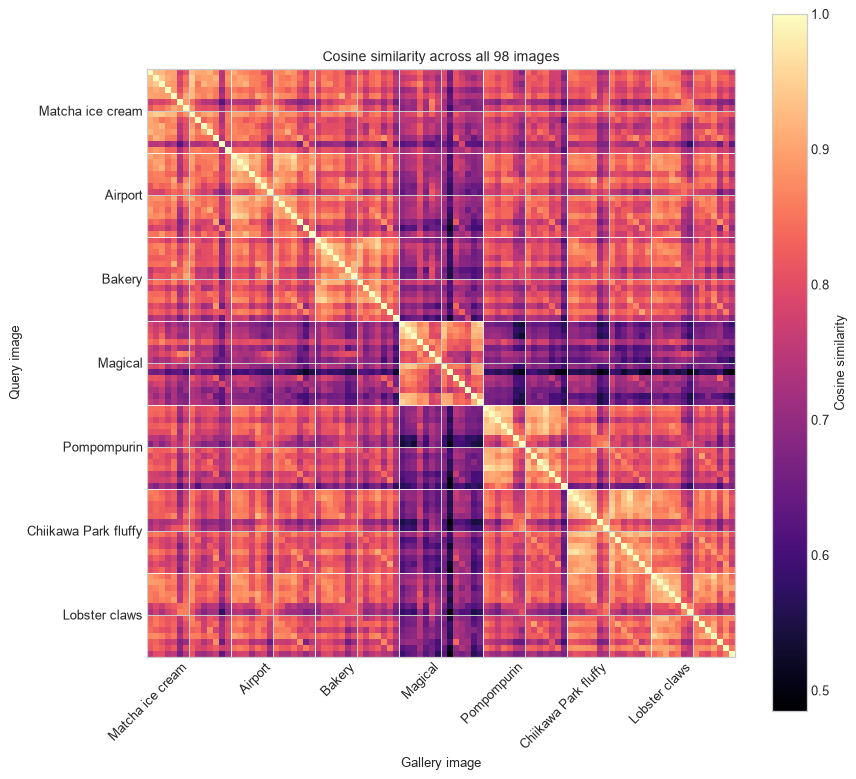

In [7]:
order = np.argsort(np.asarray(artifact.identity_ids), kind="stable")
ordered_similarity = similarity_matrix[np.ix_(order, order)]
ordered_identities = np.asarray(artifact.identity_ids)[order]

fig, axis = plt.subplots(figsize=(10, 9))
image = axis.imshow(
    ordered_similarity, cmap="magma", vmin=ordered_similarity.min(), vmax=1.0
)
axis.set_title("Cosine similarity across all 98 images")
axis.set_xlabel("Gallery image")
axis.set_ylabel("Query image")

boundaries = [0]
labels = []
centers = []
for identity in sorted(set(ordered_identities)):
    indices = np.flatnonzero(ordered_identities == identity)
    labels.append(catalog_names.get(identity, identity))
    centers.append((indices[0] + indices[-1]) / 2)
    boundaries.append(indices[-1] + 1)
for boundary in boundaries[1:-1]:
    axis.axhline(boundary - 0.5, color="white", linewidth=0.7)
    axis.axvline(boundary - 0.5, color="white", linewidth=0.7)
axis.set_xticks(centers, labels, rotation=45, ha="right")
axis.set_yticks(centers, labels)
fig.colorbar(image, ax=axis, label="Cosine similarity")
plt.tight_layout()
plt.show()

## 7. Identity prototype map

A prototype is the normalized average embedding for one identity. It compresses all 14 Session 1 photographs into one representative vector. We have not selected prototype retrieval yet, but this map offers a compact view of which identities are close in embedding space.

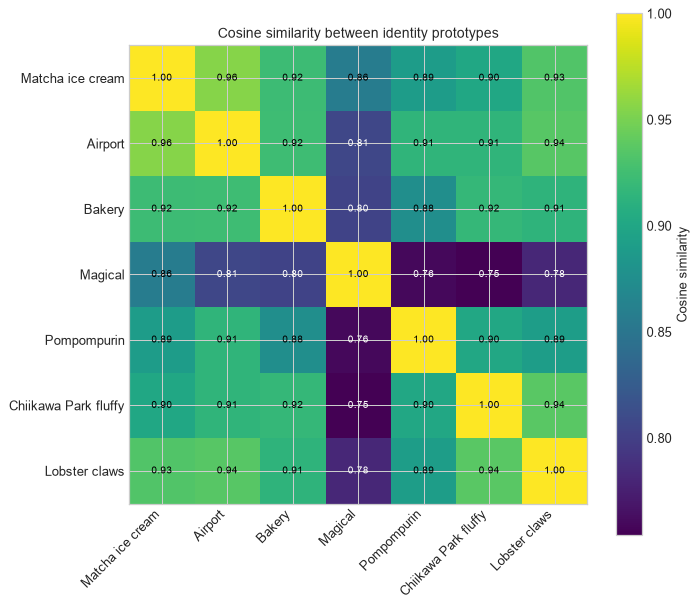

In [8]:
identity_order = sorted(set(artifact.identity_ids))
prototypes = []
for identity in identity_order:
    rows = artifact.embeddings[np.asarray(artifact.identity_ids) == identity]
    prototype = rows.mean(axis=0)
    prototype /= np.linalg.norm(prototype)
    prototypes.append(prototype)
prototype_matrix = np.asarray(prototypes) @ np.asarray(prototypes).T

fig, axis = plt.subplots(figsize=(8, 7))
image = axis.imshow(
    prototype_matrix, cmap="viridis", vmin=prototype_matrix.min(), vmax=1.0
)
labels = [catalog_names.get(identity, identity) for identity in identity_order]
axis.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
axis.set_yticks(range(len(labels)), labels)
axis.set_title("Cosine similarity between identity prototypes")
for row in range(len(labels)):
    for column in range(len(labels)):
        axis.text(
            column,
            row,
            f"{prototype_matrix[row, column]:.2f}",
            ha="center",
            va="center",
            color="white" if prototype_matrix[row, column] < 0.85 else "black",
            fontsize=8,
        )
fig.colorbar(image, ax=axis, label="Cosine similarity")
plt.tight_layout()
plt.show()

## 8. How image matches become an identity ranking

For each query, the exact same image is removed from the gallery. We calculate cosine similarity against every remaining image. For each doll identity, we retain its highest reference image score. Sorting those seven scores creates the identity ranking.

This is called **nearest image aggregation**. One strong reference can represent an identity even when its other photographs use very different views.

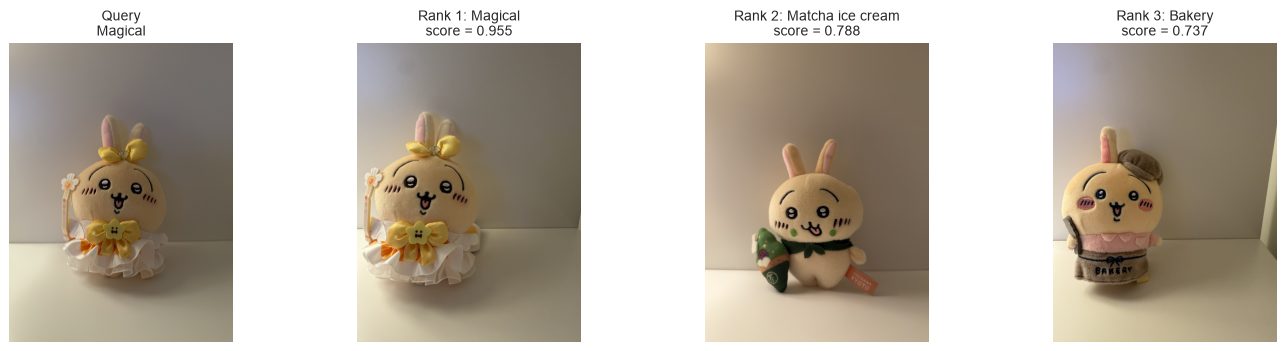

,rank,identity,score,best reference
0,1,Magical,0.9549,img-000056
1,2,Matcha ice cream,0.7879,img-000001
2,3,Bakery,0.7374,img-000039


In [9]:
example_query = next(
    query
    for query in report["queries"]
    if query["true_identity"] == sample_identity and query["true_identity_rank"] == 1
)
ranked = example_query["ranked_identities"]

fig, axes = plt.subplots(1, 1 + len(ranked), figsize=(4 * (1 + len(ranked)), 4))
draw_image(
    axes[0],
    example_query["image_id"],
    f"Query\n{catalog_names[example_query['true_identity']]}",
)
for rank, candidate in enumerate(ranked, start=1):
    draw_image(
        axes[rank],
        candidate["reference_image_id"],
        f"Rank {rank}: {catalog_names[candidate['identity_id']]}\nscore = {candidate['score']:.3f}",
    )
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        [
            {
                "rank": rank,
                "identity": catalog_names[candidate["identity_id"]],
                "score": candidate["score"],
                "best reference": candidate["reference_image_id"],
            }
            for rank, candidate in enumerate(ranked, start=1)
        ]
    ).style.format({"score": "{:.4f}"})
)

## 9. What the aggregate metrics mean

### Top 1 accuracy

The fraction of queries whose first ranked identity is correct. `1.0` is perfect and `0.0` means none are correct. Our same session value is useful as a pipeline check, but a good production value must come from Session 2 and Session 3.

### Top 3 accuracy

The fraction whose correct identity appears anywhere in the first three. A large gap between top 1 and top 3 means the model often recognizes the right neighborhood but struggles to choose the first identity. This can still support a user interface that shows several candidates.

### Macro recall

First calculate top 1 accuracy separately for each identity, then average the identity results equally. This prevents a doll with many more photographs from dominating the metric. Because Session 1 has exactly 14 images per identity, macro recall and overall top 1 accuracy are currently equal.

### Mean reciprocal rank

For each query, the correct identity receives `1 / rank`: rank 1 earns `1.0`, rank 2 earns `0.5`, rank 3 earns about `0.333`, and rank 5 earns `0.2`. We average those values. It rewards putting the correct answer near the top even when it is not first.

### What counts as good or bad

There is no trustworthy target from Session 1 because it shares capture conditions. On independent sessions, higher is better, but we should also inspect which identities fail, whether errors are confident, and whether unknown dolls are incorrectly accepted. A system with high known identity accuracy can still be unsafe if it confidently labels every unseen doll as something known.

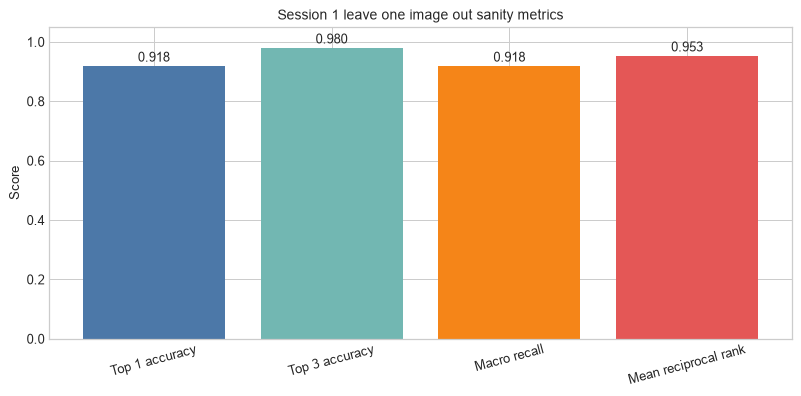

Top 1: 90 of 98 queries
Top 3: 96 of 98 queries


In [10]:
metrics = pd.Series(
    {
        "Top 1 accuracy": report["top1_accuracy"],
        "Top 3 accuracy": report["top3_accuracy"],
        "Macro recall": report["macro_recall"],
        "Mean reciprocal rank": report["mean_reciprocal_rank"],
    }
)
correct_top1 = sum(query["true_identity_rank"] == 1 for query in report["queries"])
correct_top3 = sum(query["true_identity_rank"] <= 3 for query in report["queries"])

fig, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.bar(
    metrics.index, metrics.values, color=["#4c78a8", "#72b7b2", "#f58518", "#e45756"]
)
axis.set_ylim(0, 1.05)
axis.set_ylabel("Score")
axis.set_title("Session 1 leave one image out sanity metrics")
axis.tick_params(axis="x", rotation=15)
for bar, value in zip(bars, metrics.values, strict=True):
    axis.text(
        bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.3f}", ha="center"
    )
plt.tight_layout()
plt.show()

print(f"Top 1: {correct_top1} of {report['query_count']} queries")
print(f"Top 3: {correct_top3} of {report['query_count']} queries")

## 10. Per identity accuracy and confusion matrix

Aggregate accuracy can hide one weak doll. The per identity chart gives each doll its own result. The confusion matrix shows the direction of mistakes: rows are true identities, while columns are first ranked predictions.

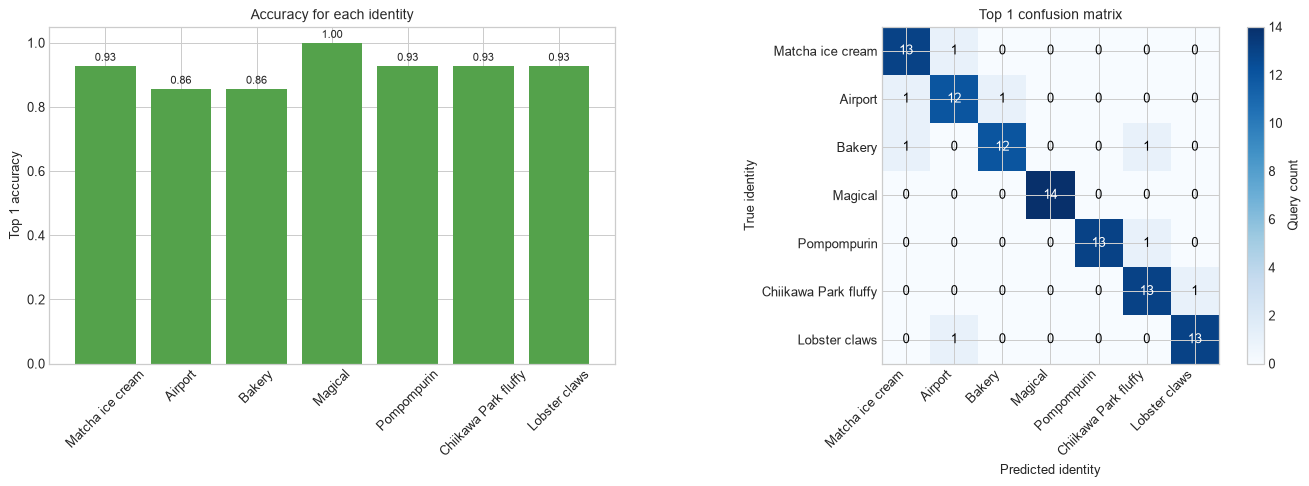

,display_name,correct,count,top 1 accuracy
true_identity,,,,
usagi-0001,Matcha ice cream,13,14,0.929
usagi-0002,Airport,12,14,0.857
usagi-0003,Bakery,12,14,0.857
usagi-0004,Magical,14,14,1.000
usagi-0005,Pompompurin,13,14,0.929
usagi-0006,Chiikawa Park fluffy,13,14,0.929
usagi-0007,Lobster claws,13,14,0.929


In [11]:
query_frame = pd.DataFrame(
    [
        {
            "image_id": query["image_id"],
            "true_identity": query["true_identity"],
            "predicted_identity": query["ranked_identities"][0]["identity_id"],
            "true_rank": query["true_identity_rank"],
            "top_score": query["ranked_identities"][0]["score"],
            "predicted_reference": query["ranked_identities"][0]["reference_image_id"],
        }
        for query in report["queries"]
    ]
)
query_frame["correct"] = (
    query_frame["true_identity"] == query_frame["predicted_identity"]
)
per_identity = query_frame.groupby("true_identity")["correct"].agg(
    ["mean", "sum", "count"]
)
per_identity["display_name"] = [
    catalog_names.get(identity, identity) for identity in per_identity.index
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].bar(per_identity["display_name"], per_identity["mean"], color="#54a24b")
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Top 1 accuracy")
axes[0].set_title("Accuracy for each identity")
axes[0].tick_params(axis="x", rotation=45)
for index, value in enumerate(per_identity["mean"]):
    axes[0].text(index, value + 0.015, f"{value:.2f}", ha="center", fontsize=9)

confusion = pd.crosstab(query_frame["true_identity"], query_frame["predicted_identity"])
confusion = confusion.reindex(
    index=identity_order, columns=identity_order, fill_value=0
)
heat = axes[1].imshow(confusion.to_numpy(), cmap="Blues")
axes[1].set_xticks(
    range(len(identity_order)),
    [catalog_names[x] for x in identity_order],
    rotation=45,
    ha="right",
)
axes[1].set_yticks(
    range(len(identity_order)), [catalog_names[x] for x in identity_order]
)
axes[1].set_xlabel("Predicted identity")
axes[1].set_ylabel("True identity")
axes[1].set_title("Top 1 confusion matrix")
for row in range(len(identity_order)):
    for column in range(len(identity_order)):
        axes[1].text(
            column,
            row,
            int(confusion.iloc[row, column]),
            ha="center",
            va="center",
            color="white" if confusion.iloc[row, column] > 7 else "black",
        )
fig.colorbar(heat, ax=axes[1], label="Query count")
plt.tight_layout()
plt.show()

display(
    per_identity[["display_name", "sum", "count", "mean"]]
    .rename(columns={"sum": "correct", "mean": "top 1 accuracy"})
    .style.format({"top 1 accuracy": "{:.3f}"})
)

## 11. Every incorrect top 1 prediction

The table identifies each incorrect query, the true doll, the first prediction, the cosine score of that prediction, and the rank of the true identity. A true rank greater than three explains a top 3 failure.

In [12]:
observed_condition = {
    "img-000013": "shared blanket occlusion",
    "img-000026": "handheld view",
    "img-000027": "shared blanket occlusion",
    "img-000040": "handheld view",
    "img-000041": "shared blanket occlusion",
    "img-000063": "side or rear view with fewer face details",
    "img-000079": "unusual low or lying view",
    "img-000096": "handheld view",
}

wrong = query_frame.loc[~query_frame["correct"]].copy()
wrong["true doll"] = wrong["true_identity"].map(catalog_names)
wrong["predicted doll"] = wrong["predicted_identity"].map(catalog_names)
wrong["visible condition"] = (
    wrong["image_id"].map(observed_condition).fillna("review manually")
)
display(
    wrong[
        [
            "image_id",
            "true doll",
            "predicted doll",
            "top_score",
            "true_rank",
            "predicted_reference",
            "visible condition",
        ]
    ].style.format({"top_score": "{:.4f}"})
)

,image_id,true doll,predicted doll,top_score,true_rank,predicted_reference,visible condition
12,img-000013,Matcha ice cream,Airport,0.8634,6,img-000027,shared blanket occlusion
25,img-000026,Airport,Matcha ice cream,0.9032,2,img-000012,handheld view
26,img-000027,Airport,Bakery,0.8709,2,img-000041,shared blanket occlusion
39,img-000040,Bakery,Matcha ice cream,0.8888,5,img-000012,handheld view
40,img-000041,Bakery,Chiikawa Park fluffy,0.9029,2,img-000083,shared blanket occlusion
62,img-000063,Pompompurin,Chiikawa Park fluffy,0.8825,2,img-000077,side or rear view with fewer face details
78,img-000079,Chiikawa Park fluffy,Lobster claws,0.9059,2,img-000093,unusual low or lying view
95,img-000096,Lobster claws,Airport,0.8836,2,img-000026,handheld view


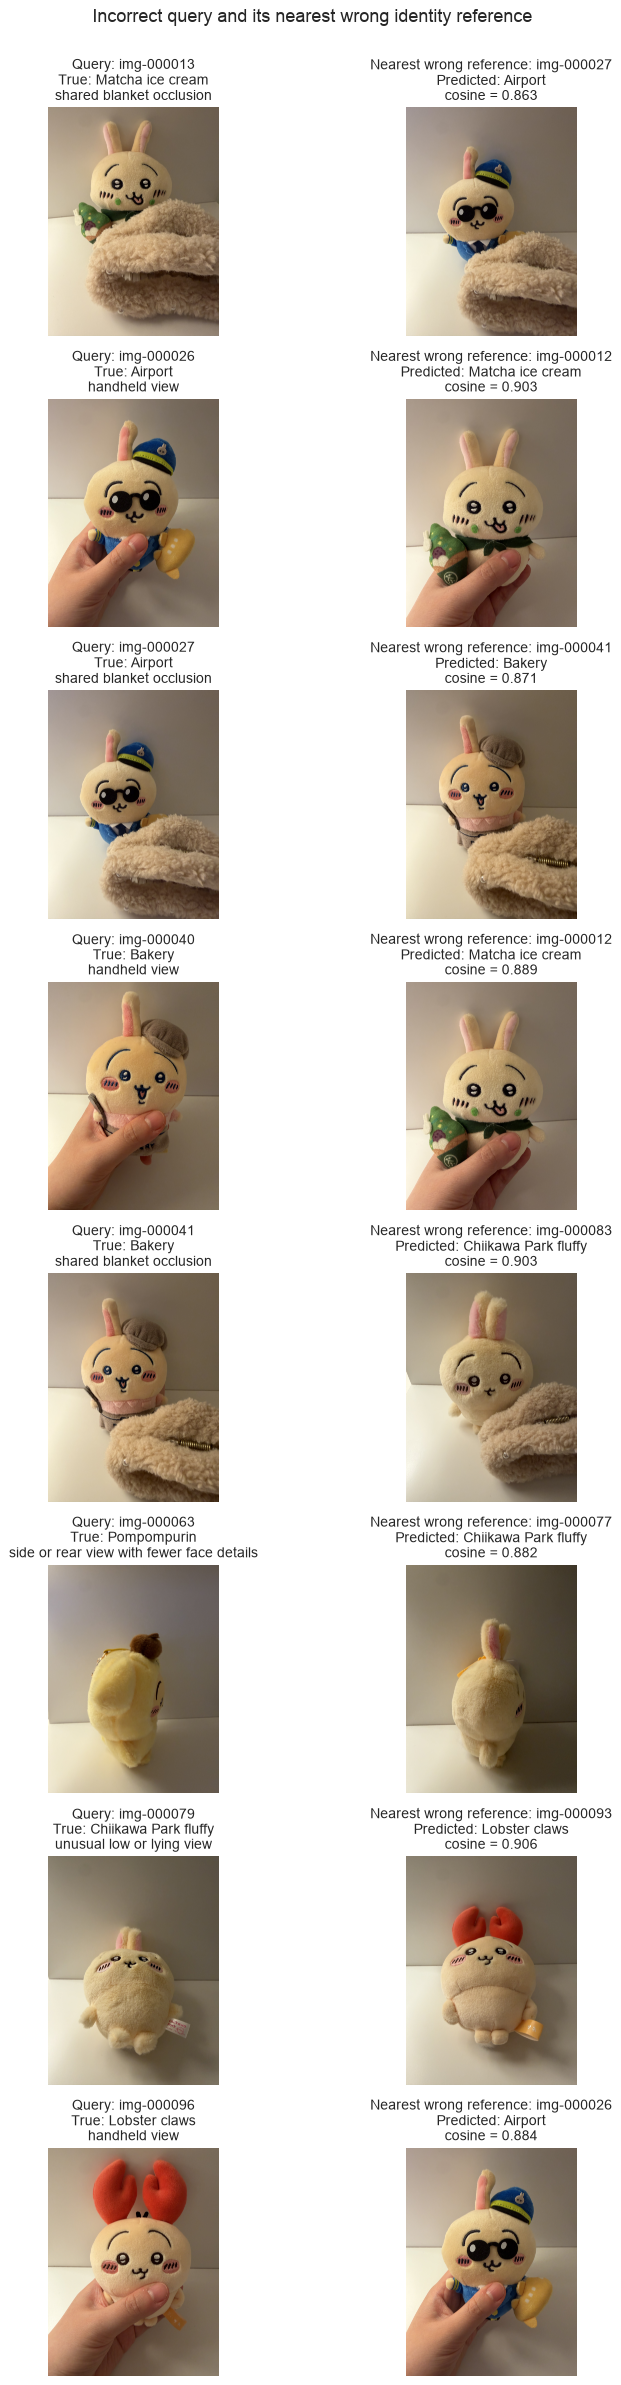

In [13]:
fig, axes = plt.subplots(len(wrong), 2, figsize=(10, 3.3 * len(wrong)))
for row_number, (_, row) in enumerate(wrong.iterrows()):
    draw_image(
        axes[row_number, 0],
        row["image_id"],
        f"Query: {row['image_id']}\nTrue: {catalog_names[row['true_identity']]}\n{observed_condition.get(row['image_id'], '')}",
    )
    draw_image(
        axes[row_number, 1],
        row["predicted_reference"],
        f"Nearest wrong reference: {row['predicted_reference']}\nPredicted: {catalog_names[row['predicted_identity']]}\ncosine = {row['top_score']:.3f}",
    )
plt.suptitle(
    "Incorrect query and its nearest wrong identity reference", y=1.002, fontsize=14
)
plt.tight_layout()
plt.show()

## 12. Interpreting the mistakes

Six of the eight top 1 mistakes involve the shared blanket or a handheld view. The likely issue is a shortcut: the query may be unusually similar to reference images that share the hand or blanket even when the doll identity differs.

The remaining errors use views with fewer face, costume, or accessory details. DINOv2 was trained as a general image representation. It does not know that a small bow, hat, prop, or outfit is the identity defining evidence for this project.

Possible causes include:

1. **Shared occluder shortcut.** The same hand or blanket appears across identities and can dominate the image.
2. **Background shortcut.** Every Session 1 photograph uses a similar scene, so same session performance can look better than new session performance.
3. **Small identifying details.** Image resizing may make a bow, tag, prop, or embroidery detail occupy very few pixels.
4. **Viewpoint loss.** Rear, side, low, or lying views can hide the strongest identity cues.
5. **Nearest image sensitivity.** One visually similar but wrong reference can win even when the correct identity has several moderately similar references.
6. **No task specific training.** The frozen model has never been taught which differences matter between these dolls.

These are hypotheses for Session 2 to test. We should not fine tune based only on this same session review.

## 13. What comes next

1. Capture Session 2 with a different background, lighting, placement, and a mix of tag visibility.
2. Keep Session 1 as the only gallery.
3. Use every Session 2 image as an independent validation query.
4. Compare nearest image aggregation with normalized identity prototypes.
5. Add unknown objects and unseen dolls before choosing an acceptance threshold.
6. Consider fine tuning only after the independent validation result exposes a clear limitation.

Session 2 accuracy will probably be lower than this Session 1 sanity result. That is expected and more informative. A lower honest result is better than a high result caused by shared capture conditions.